# Bankruptcy Prediction — Data Cleaning and Preprocessing

## Project Overview

In the previous notebook, we completed Exploratory Data Analysis.

In this notebook, we prepare the dataset for machine learning by cleaning and preprocessing the data.

### Objectives of this notebook

- Load the dataset
- Convert the target variable into numeric format
- Check missing values
- Check duplicate records
- Check invalid values
- Handle outliers
- Separate features and target variable
- Scale numerical features
- Save the cleaned dataset for model building

### Target Variable

`Bankrupt`

- `0` = Healthy company
- `1` = Bankrupt company

## 1. Import Required Libraries

First, we import the required Python libraries for data cleaning and preprocessing.

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

# Visualization style
sns.set_style("whitegrid")

%matplotlib inline

In [2]:
# Load dataset
df = pd.read_csv("../data/bankruptcy.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (6819, 95)


,Bankrupt,ROA_C_Before_Interest_Depreciation,ROA_A_Before_Interest_After_Tax,ROA_B_Before_Interest_Depreciation_After_Tax,Operating_Gross_Margin,Realized_Sales_Gross_Margin,Operating_Profit_Rate,PreTax_Net_Interest_Rate,AfterTax_Net_Interest_Rate,NonIndustry_Income_Expenditure_Revenue,Continuous_Interest_Rate_After_Tax,Operating_Expense_Rate,R&D_Expense_Rate,Cash_Flow_Rate,InterestBearing_Debt_Interest_Rate,Tax_Rate_A,Net_Value_Per_Share_B,Net_Value_Per_Share_A,Net_Value_Per_Share_C,Persistent_EPS_Last_4_Seasons,Cash_Flow_Per_Share,Revenue_Per_Share,Operating_Profit_Per_Share,Net_Profit_Before_Tax_Per_Share,Realized_Sales_Gross_Profit_Growth_Rate,Operating_Profit_Growth_Rate,AfterTax_Net_Profit_Growth_Rate,Regular_Net_Profit_Growth_Rate,Continuous_Net_Profit_Growth_Rate,Total_Asset_Growth_Rate,Net_Value_Growth_Rate,Total_Asset_Return_Growth_Rate,Cash_Reinvestment_Percent,Current_Ratio,Quick_Ratio,Interest_Expense_Ratio,Total_Debt_to_Net_Worth,Debt_Ratio_Percent,Net_Worth_to_Assets,LongTerm_Fund_Suitability_Ratio_A,Borrowing_Dependency,Contingent_Liabilities_to_Net_Worth,Operating_Profit_to_PaidIn_Capital,Net_Profit_Before_Tax_to_PaidIn_Capital,Inventory_Accounts_Receivable_to_Net_Value,Total_Asset_Turnover,Accounts_Receivable_Turnover,Average_Collection_Days,Inventory_Turnover_Rate,Fixed_Assets_Turnover_Frequency,Net_Worth_Turnover_Rate,Revenue_Per_Person,Operating_Profit_Per_Person,Allocation_Rate_Per_Person,Working_Capital_to_Total_Assets,Quick_Assets_to_Total_Assets,Current_Assets_to_Total_Assets,Cash_to_Total_Assets,Quick_Assets_to_Current_Liability,Cash_to_Current_Liability,Current_Liability_to_Assets,Operating_Funds_to_Liability,Inventory_to_Working_Capital,Inventory_to_Current_Liability,Current_Liabilities_to_Liability,Working_Capital_to_Equity,Current_Liabilities_to_Equity,LongTerm_Liability_to_Current_Assets,Retained_Earnings_to_Total_Assets,Total_Income_to_Total_Expense,Total_Expense_to_Assets,Current_Asset_Turnover_Rate,Quick_Asset_Turnover_Rate,Working_Capital_Turnover_Rate,Cash_Turnover_Rate,Cash_Flow_to_Sales,Fixed_Assets_to_Assets,Current_Liability_to_Liability,Current_Liability_to_Equity,Equity_to_LongTerm_Liability,Cash_Flow_to_Total_Assets,Cash_Flow_to_Liability,CFO_to_Assets,Cash_Flow_to_Equity,Current_Liability_to_Current_Assets,Liability_Assets_Flag,Net_Income_to_Total_Assets,Total_Assets_to_GNP_Price,NoCredit_Interval,Gross_Profit_to_Sales,Net_Income_to_Stockholders_Equity,Liability_to_Equity,DFL,Interest_Coverage_Ratio,Equity_to_Liability
0,No,0.5718,0.6424,0.6347,0.6262,0.6262,0.9992,0.7977,0.8097,0.3036,0.7819,0.0003,0.0003,0.4778,0.0006,0.0015,0.2163,0.2163,0.2163,0.2580,0.3322,0.0268,0.1291,0.2057,0.0221,0.8480,0.6894,0.6894,0.2176,8550000000.0000,0.0006,0.2641,0.3809,0.0148,0.0135,0.6306,0.0017,0.0457,0.9543,0.0066,0.3696,0.0054,0.1281,0.2035,0.3963,0.1154,0.0010,0.0060,0.0003,0.0004,0.0245,0.0262,0.4156,0.0080,0.8141,0.3792,0.3891,0.2145,0.0139,0.0227,0.0498,0.3890,0.2770,0.0025,0.9808,0.7350,0.3277,0.0000,0.9538,0.0026,0.0310,0.0001,0.0001,0.5940,0.0002,0.6715,0.1262,0.9808,0.3277,0.1109,0.5966,0.4350,0.6407,0.3094,0.0198,0,0.8544,0.0078,0.6240,0.6262,0.8433,0.2760,0.0268,0.5652,0.0840
1,No,0.4946,0.5498,0.5434,0.6021,0.6021,0.9990,0.7974,0.8093,0.3035,0.7816,0.0001,5600000000.0000,0.4591,0.0008,0.0824,0.1731,0.1731,0.1731,0.2199,0.3122,0.0526,0.1014,0.1746,0.0224,0.8482,0.6899,0.6899,0.2176,7150000000.0000,0.0005,0.2646,0.3651,0.0091,0.0054,0.6317,0.0088,0.1455,0.8545,0.0060,0.3725,0.0054,0.1013,0.1737,0.4106,0.2414,0.0009,0.0070,0.0001,0.0010,0.0597,0.0249,0.3940,0.0030,0.8199,0.4728,0.7421,0.0834,0.0056,0.0029,0.1517,0.3339,0.2775,0.0094,0.9920,0.7375,0.3340,3490000000.0000,0.9341,0.0023,0.0362,0.0001,7720000000.0000,0.5939,3900000000.0000,0.6716,0.1140,0.9920,0.3340,0.1110,0.5904,0.4501,0.5327,0.3049,0.0319,0,0.8041,0.0070,0.6237,0.6021,0.8408,0.2812,0.0272,0.5666,0.0251
2,No,0.4653,0.5156,0.5116,0.5938,0.5938,0.9990,0.7974,0.8093,0.3035,0.7815,1110000000.0000,67900000.0000,0.4630,0.0002,0.000

## 2. Handle Missing and Invalid Values

In this section, we check and handle missing or invalid values.

Missing values and invalid values such as infinity can cause errors during preprocessing and model training.

We check for:

- Missing values
- Infinite values
- Invalid numeric values

If any invalid values are found, they will be replaced and handled safely.

In [3]:
# Check missing values
missing_values = df.isnull().sum().sum()

print("Missing values:", missing_values)

Missing values: 0


In [4]:
# Check infinite values in numerical columns
numeric_df = df.select_dtypes(include=[np.number])

infinite_values = np.isinf(numeric_df).sum().sum()

print("Infinite values:", infinite_values)

Infinite values: 0


In [5]:
# Replace infinite values with NaN
df = df.replace([np.inf, -np.inf], np.nan)

# Fill missing values using median if any exist
if df.isnull().sum().sum() > 0:
    df = df.fillna(df.median(numeric_only=True))
    print("Missing or invalid values handled using median.")
else:
    print("No missing or invalid values found.")

No missing or invalid values found.


### Observation

The dataset does not contain missing values.

The dataset was also checked for infinite values.  
If any invalid values existed, they were replaced and handled using median values.

This ensures that the dataset is safe for the next preprocessing steps.

## 3. Imputation

Imputation is the process of filling missing values.

In the previous step, we checked the dataset and found that there are no missing values.

However, to make the preprocessing workflow safe, we still create a separate copy of the dataset for the next steps.

If missing values appear later, they can be filled using the median value of each numerical column.

In [6]:
# Check missing values after handling invalid values
nan_count = df.isnull().sum().sum()

print("NaN count:", nan_count)

# Create a copy for imputation step
df_imputed = df.copy()

# Apply median imputation only if missing values exist
if nan_count > 0:
    df_imputed = df_imputed.fillna(df_imputed.median(numeric_only=True))
    print("Missing values were filled using median values.")
else:
    print("No missing values found. Imputation was not required.")

NaN count: 0
No missing values found. Imputation was not required.


### Observation

The dataset contains **0 missing values** after checking and handling invalid values.

Therefore, no actual imputation was required.

A clean copy of the dataset was created as `df_imputed` so that the next preprocessing steps can continue safely.

## 4. Distribution Check After Imputation

In this section, we compare feature distributions before and after the imputation step.

Since the dataset does not contain missing values, no actual imputation was required.

This comparison is included to confirm that the data distribution remains unchanged after the imputation check.

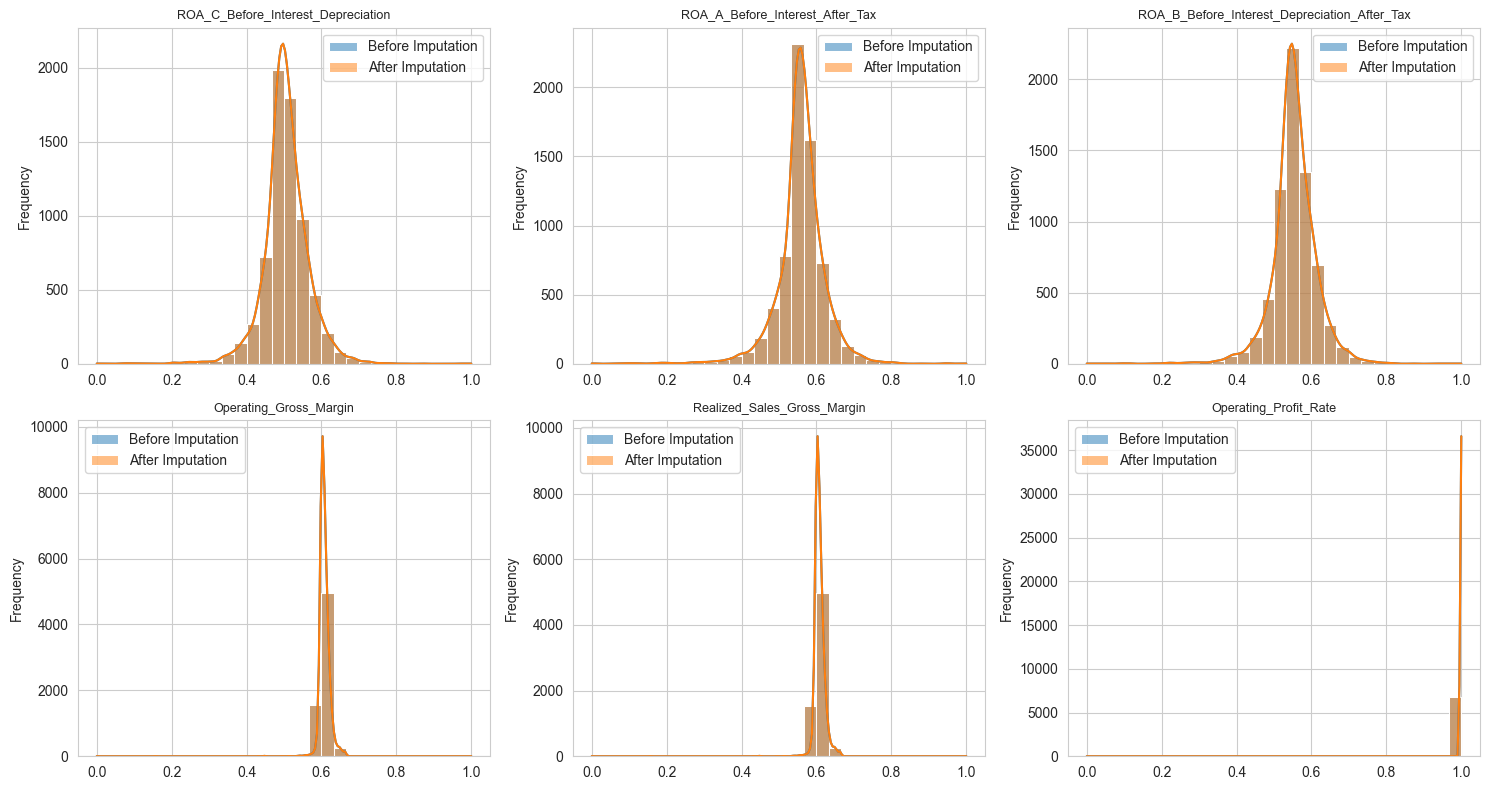

In [7]:
# Select first 6 numerical columns for comparison
numeric_cols_for_plot = df.select_dtypes(include=[np.number]).columns[:6].tolist()

# Create distribution comparison plots
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols_for_plot):
    sns.histplot(
        df[col].dropna(),
        bins=30,
        kde=True,
        label="Before Imputation",
        ax=axes[i],
        alpha=0.5
    )
    
    sns.histplot(
        df_imputed[col].dropna(),
        bins=30,
        kde=True,
        label="After Imputation",
        ax=axes[i],
        alpha=0.5
    )
    
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequency")
    axes[i].legend()

plt.tight_layout()
plt.show()

### Observation

The distributions before and after the imputation step are the same.

This is expected because the dataset contains **0 missing values**, so no imputation was actually applied.

The dataset is now ready for the next preprocessing step.

Next, we will handle outliers separately because financial ratio datasets often contain extreme values.

## 5. Feature Engineering

Feature engineering is the process of creating new useful features from existing columns.

In this project, we create three aggregate financial indicators:

- `AvgProfitability`
- `AvgLeverage`
- `AvgLiquidity`

These new features summarize related financial ratios and may help the machine learning model understand company financial health more clearly.

In [8]:
# Create a copy before feature engineering
df_featured = df_imputed.copy()

# Identify profitability-related columns
profitability_cols = [
    col for col in df_featured.columns
    if any(keyword in col for keyword in ["ROA", "Net_Income", "Profit_Margin"])
]

# Identify leverage-related columns
leverage_cols = [
    col for col in df_featured.columns
    if any(keyword in col for keyword in ["Liability", "Debt", "Borrowing"])
]

# Identify liquidity-related columns
liquidity_cols = [
    col for col in df_featured.columns
    if any(keyword in col for keyword in ["Quick_Ratio", "Current_Ratio", "Cash"])
]

# Create aggregate features
if profitability_cols:
    df_featured["AvgProfitability"] = df_featured[profitability_cols].mean(axis=1)

if leverage_cols:
    df_featured["AvgLeverage"] = df_featured[leverage_cols].mean(axis=1)

if liquidity_cols:
    df_featured["AvgLiquidity"] = df_featured[liquidity_cols].mean(axis=1)

print("Shape before feature engineering:", df_imputed.shape)
print("Shape after feature engineering:", df_featured.shape)

df_featured.head()

Shape before feature engineering: (6819, 95)
Shape after feature engineering: (6819, 98)


,Bankrupt,ROA_C_Before_Interest_Depreciation,ROA_A_Before_Interest_After_Tax,ROA_B_Before_Interest_Depreciation_After_Tax,Operating_Gross_Margin,Realized_Sales_Gross_Margin,Operating_Profit_Rate,PreTax_Net_Interest_Rate,AfterTax_Net_Interest_Rate,NonIndustry_Income_Expenditure_Revenue,Continuous_Interest_Rate_After_Tax,Operating_Expense_Rate,R&D_Expense_Rate,Cash_Flow_Rate,InterestBearing_Debt_Interest_Rate,Tax_Rate_A,Net_Value_Per_Share_B,Net_Value_Per_Share_A,Net_Value_Per_Share_C,Persistent_EPS_Last_4_Seasons,Cash_Flow_Per_Share,Revenue_Per_Share,Operating_Profit_Per_Share,Net_Profit_Before_Tax_Per_Share,Realized_Sales_Gross_Profit_Growth_Rate,Operating_Profit_Growth_Rate,AfterTax_Net_Profit_Growth_Rate,Regular_Net_Profit_Growth_Rate,Continuous_Net_Profit_Growth_Rate,Total_Asset_Growth_Rate,Net_Value_Growth_Rate,Total_Asset_Return_Growth_Rate,Cash_Reinvestment_Percent,Current_Ratio,Quick_Ratio,Interest_Expense_Ratio,Total_Debt_to_Net_Worth,Debt_Ratio_Percent,Net_Worth_to_Assets,LongTerm_Fund_Suitability_Ratio_A,Borrowing_Dependency,Contingent_Liabilities_to_Net_Worth,Operating_Profit_to_PaidIn_Capital,Net_Profit_Before_Tax_to_PaidIn_Capital,Inventory_Accounts_Receivable_to_Net_Value,Total_Asset_Turnover,Accounts_Receivable_Turnover,Average_Collection_Days,Inventory_Turnover_Rate,Fixed_Assets_Turnover_Frequency,Net_Worth_Turnover_Rate,Revenue_Per_Person,Operating_Profit_Per_Person,Allocation_Rate_Per_Person,Working_Capital_to_Total_Assets,Quick_Assets_to_Total_Assets,Current_Assets_to_Total_Assets,Cash_to_Total_Assets,Quick_Assets_to_Current_Liability,Cash_to_Current_Liability,Current_Liability_to_Assets,Operating_Funds_to_Liability,Inventory_to_Working_Capital,Inventory_to_Current_Liability,Current_Liabilities_to_Liability,Working_Capital_to_Equity,Current_Liabilities_to_Equity,LongTerm_Liability_to_Current_Assets,Retained_Earnings_to_Total_Assets,Total_Income_to_Total_Expense,Total_Expense_to_Assets,Current_Asset_Turnover_Rate,Quick_Asset_Turnover_Rate,Working_Capital_Turnover_Rate,Cash_Turnover_Rate,Cash_Flow_to_Sales,Fixed_Assets_to_Assets,Current_Liability_to_Liability,Current_Liability_to_Equity,Equity_to_LongTerm_Liability,Cash_Flow_to_Total_Assets,Cash_Flow_to_Liability,CFO_to_Assets,Cash_Flow_to_Equity,Current_Liability_to_Current_Assets,Liability_Assets_Flag,Net_Income_to_Total_Assets,Total_Assets_to_GNP_Price,NoCredit_Interval,Gross_Profit_to_Sales,Net_Income_to_Stockholders_Equity,Liability_to_Equity,DFL,Interest_Coverage_Ratio,Equity_to_Liability,AvgProfitability,AvgLeverage,AvgLiquidity
0,No,0.5718,0.6424,0.6347,0.6262,0.6262,0.9992,0.7977,0.8097,0.3036,0.7819,0.0003,0.0003,0.4778,0.0006,0.0015,0.2163,0.2163,0.2163,0.2580,0.3322,0.0268,0.1291,0.2057,0.0221,0.8480,0.6894,0.6894,0.2176,8550000000.0000,0.0006,0.2641,0.3809,0.0148,0.0135,0.6306,0.0017,0.0457,0.9543,0.0066,0.3696,0.0054,0.1281,0.2035,0.3963,0.1154,0.0010,0.0060,0.0003,0.0004,0.0245,0.0262,0.4156,0.0080,0.8141,0.3792,0.3891,0.2145,0.0139,0.0227,0.0498,0.3890,0.2770,0.0025,0.9808,0.7350,0.3277,0.0000,0.9538,0.0026,0.0310,0.0001,0.0001,0.5940,0.0002,0.6715,0.1262,0.9808,0.3277,0.1109,0.5966,0.4350,0.6407,0.3094,0.0198,0,0.8544,0.0078,0.6240,0.6262,0.8433,0.2760,0.0268,0.5652,0.0840,0.7093,0.2164,0.2891
1,No,0.4946,0.5498,0.5434,0.6021,0.6021,0.9990,0.7974,0.8093,0.3035,0.7816,0.0001,5600000000.0000,0.4591,0.0008,0.0824,0.1731,0.1731,0.1731,0.2199,0.3122,0.0526,0.1014,0.1746,0.0224,0.8482,0.6899,0.6899,0.2176,7150000000.0000,0.0005,0.2646,0.3651,0.0091,0.0054,0.6317,0.0088,0.1455,0.8545,0.0060,0.3725,0.0054,0.1013,0.1737,0.4106,0.2414,0.0009,0.0070,0.0001,0.0010,0.0597,0.0249,0.3940,0.0030,0.8199,0.4728,0.7421,0.0834,0.0056,0.0029,0.1517,0.3339,0.2775,0.0094,0.9920,0.7375,0.3340,3490000000.0000,0.9341,0.0023,0.0362,0.0001,7720000000.0000,0.5939,3900000000.0000,0.6716,0.1140,0.9920,0.3340,0.1110,0.5904,0.4501,0.5327,0.3049,0.0319,0,0.8041,0.0070,0.6237,0.6021,0.8408,0.2812,0.0272,0.5666,0.0251,0.6465,183684210.7499,325000000.2712
2,No,0.4653,0.5156,0.511

### Observation

After feature engineering, the dataset shape changed from **95 columns** to **98 columns**.

Three new aggregate features were created:

- `AvgProfitability`
- `AvgLeverage`
- `AvgLiquidity`

These features summarize important financial areas related to company performance, debt level, and short-term financial strength.

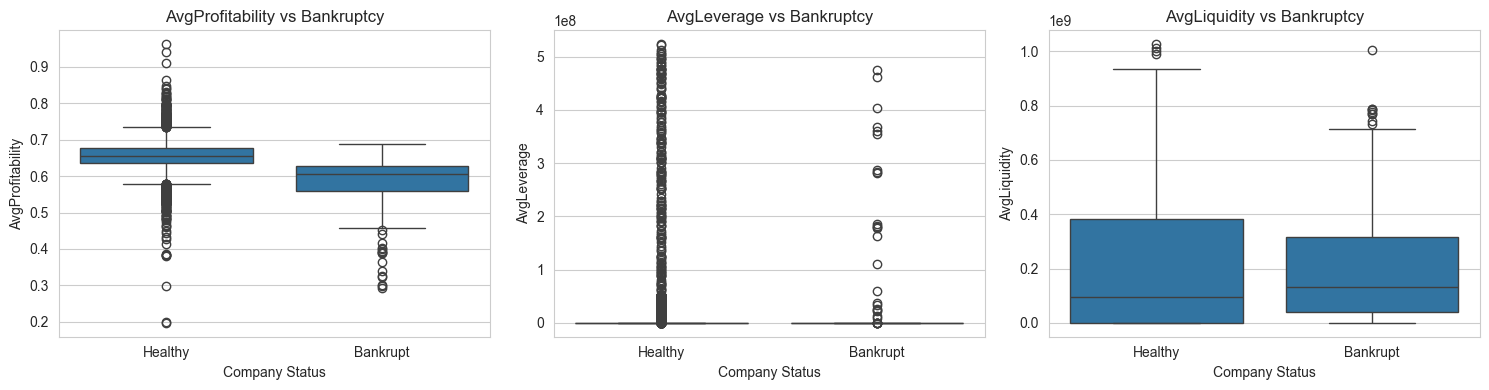

In [9]:
# Select engineered features
engineered_features = [
    col for col in ["AvgProfitability", "AvgLeverage", "AvgLiquidity"]
    if col in df_featured.columns
]

# Plot engineered features against target variable
fig, axes = plt.subplots(1, len(engineered_features), figsize=(5 * len(engineered_features), 4))

if len(engineered_features) == 1:
    axes = [axes]

for ax, col in zip(axes, engineered_features):
    sns.boxplot(
        data=df_featured,
        x="Bankrupt",
        y=col,
        ax=ax
    )
    
    ax.set_title(f"{col} vs Bankruptcy")
    ax.set_xlabel("Company Status")
    ax.set_ylabel(col)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Healthy", "Bankrupt"])

plt.tight_layout()
plt.show()

### Observation

The engineered features show differences between healthy and bankrupt companies.

`AvgProfitability` appears lower for bankrupt companies, which suggests that companies with weaker profitability may have higher bankruptcy risk.

`AvgLeverage` and `AvgLiquidity` also show different patterns between the two classes.

These engineered features may be useful during model training.  
However, because some features still contain outliers, outlier handling and scaling should be done before final model building.

## 6. Encode Categorical Features

Encoding is the process of converting categorical values into numerical values.

Machine learning models require numerical input, so categorical columns must be encoded before model training.

In this dataset, most features are already numerical.  
However, we still check for:

- Object/string columns
- Boolean columns

If boolean columns exist, they are converted into integer values.

In [10]:
# Create a copy before encoding
df_encoded = df_featured.copy()

# Check object columns
object_cols = df_encoded.select_dtypes(include=["object"]).columns.tolist()

# Check boolean columns
bool_cols = df_encoded.select_dtypes(include=["bool"]).columns.tolist()

print("Object columns:", object_cols)
print("Boolean columns:", bool_cols)

Object columns: ['Bankrupt']
Boolean columns: []


In [11]:
# Convert boolean columns to integer if any exist
if len(bool_cols) > 0:
    df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)
    print("Boolean columns converted to integer.")
else:
    print("No boolean columns found.")

# Final shape after encoding
print("Shape after encoding:", df_encoded.shape)

No boolean columns found.
Shape after encoding: (6819, 98)


### Observation

The dataset does not contain categorical text columns that require encoding.

Most columns are already numerical financial ratio features.

If any boolean columns exist, they are converted into integer format.

The dataset shape remains **6,819 rows and 98 columns**, which means no new columns were added during encoding.

## 7. Verify and Save Cleaned Dataset

In this section, we verify the final cleaned dataset before saving it.

We check:

- Missing values
- Final dataset shape
- Data types
- Target variable distribution

After verification, the cleaned dataset is saved as:

`data/bankruptcy_cleaned.csv`

This cleaned file will be used in the model building notebook.

In [12]:
# Verify final cleaned dataset
print("Missing values:", df_encoded.isnull().sum().sum())
print("Final shape:", df_encoded.shape)

print("\nData types:")
print(df_encoded.dtypes.value_counts())

print("\nTarget variable distribution:")
print(df_encoded["Bankrupt"].value_counts())

Missing values: 0
Final shape: (6819, 98)

Data types:
float64    96
str         1
int64       1
Name: count, dtype: int64

Target variable distribution:
Bankrupt
No     6599
Yes     220
Name: count, dtype: int64


In [13]:
# Save cleaned dataset
df_encoded.to_csv("../data/bankruptcy_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")
print("File path: ../data/bankruptcy_cleaned.csv")

Cleaned dataset saved successfully.
File path: ../data/bankruptcy_cleaned.csv


In [14]:
# Preview cleaned dataset
df_encoded.head()

,Bankrupt,ROA_C_Before_Interest_Depreciation,ROA_A_Before_Interest_After_Tax,ROA_B_Before_Interest_Depreciation_After_Tax,Operating_Gross_Margin,Realized_Sales_Gross_Margin,Operating_Profit_Rate,PreTax_Net_Interest_Rate,AfterTax_Net_Interest_Rate,NonIndustry_Income_Expenditure_Revenue,Continuous_Interest_Rate_After_Tax,Operating_Expense_Rate,R&D_Expense_Rate,Cash_Flow_Rate,InterestBearing_Debt_Interest_Rate,Tax_Rate_A,Net_Value_Per_Share_B,Net_Value_Per_Share_A,Net_Value_Per_Share_C,Persistent_EPS_Last_4_Seasons,Cash_Flow_Per_Share,Revenue_Per_Share,Operating_Profit_Per_Share,Net_Profit_Before_Tax_Per_Share,Realized_Sales_Gross_Profit_Growth_Rate,Operating_Profit_Growth_Rate,AfterTax_Net_Profit_Growth_Rate,Regular_Net_Profit_Growth_Rate,Continuous_Net_Profit_Growth_Rate,Total_Asset_Growth_Rate,Net_Value_Growth_Rate,Total_Asset_Return_Growth_Rate,Cash_Reinvestment_Percent,Current_Ratio,Quick_Ratio,Interest_Expense_Ratio,Total_Debt_to_Net_Worth,Debt_Ratio_Percent,Net_Worth_to_Assets,LongTerm_Fund_Suitability_Ratio_A,Borrowing_Dependency,Contingent_Liabilities_to_Net_Worth,Operating_Profit_to_PaidIn_Capital,Net_Profit_Before_Tax_to_PaidIn_Capital,Inventory_Accounts_Receivable_to_Net_Value,Total_Asset_Turnover,Accounts_Receivable_Turnover,Average_Collection_Days,Inventory_Turnover_Rate,Fixed_Assets_Turnover_Frequency,Net_Worth_Turnover_Rate,Revenue_Per_Person,Operating_Profit_Per_Person,Allocation_Rate_Per_Person,Working_Capital_to_Total_Assets,Quick_Assets_to_Total_Assets,Current_Assets_to_Total_Assets,Cash_to_Total_Assets,Quick_Assets_to_Current_Liability,Cash_to_Current_Liability,Current_Liability_to_Assets,Operating_Funds_to_Liability,Inventory_to_Working_Capital,Inventory_to_Current_Liability,Current_Liabilities_to_Liability,Working_Capital_to_Equity,Current_Liabilities_to_Equity,LongTerm_Liability_to_Current_Assets,Retained_Earnings_to_Total_Assets,Total_Income_to_Total_Expense,Total_Expense_to_Assets,Current_Asset_Turnover_Rate,Quick_Asset_Turnover_Rate,Working_Capital_Turnover_Rate,Cash_Turnover_Rate,Cash_Flow_to_Sales,Fixed_Assets_to_Assets,Current_Liability_to_Liability,Current_Liability_to_Equity,Equity_to_LongTerm_Liability,Cash_Flow_to_Total_Assets,Cash_Flow_to_Liability,CFO_to_Assets,Cash_Flow_to_Equity,Current_Liability_to_Current_Assets,Liability_Assets_Flag,Net_Income_to_Total_Assets,Total_Assets_to_GNP_Price,NoCredit_Interval,Gross_Profit_to_Sales,Net_Income_to_Stockholders_Equity,Liability_to_Equity,DFL,Interest_Coverage_Ratio,Equity_to_Liability,AvgProfitability,AvgLeverage,AvgLiquidity
0,No,0.5718,0.6424,0.6347,0.6262,0.6262,0.9992,0.7977,0.8097,0.3036,0.7819,0.0003,0.0003,0.4778,0.0006,0.0015,0.2163,0.2163,0.2163,0.2580,0.3322,0.0268,0.1291,0.2057,0.0221,0.8480,0.6894,0.6894,0.2176,8550000000.0000,0.0006,0.2641,0.3809,0.0148,0.0135,0.6306,0.0017,0.0457,0.9543,0.0066,0.3696,0.0054,0.1281,0.2035,0.3963,0.1154,0.0010,0.0060,0.0003,0.0004,0.0245,0.0262,0.4156,0.0080,0.8141,0.3792,0.3891,0.2145,0.0139,0.0227,0.0498,0.3890,0.2770,0.0025,0.9808,0.7350,0.3277,0.0000,0.9538,0.0026,0.0310,0.0001,0.0001,0.5940,0.0002,0.6715,0.1262,0.9808,0.3277,0.1109,0.5966,0.4350,0.6407,0.3094,0.0198,0,0.8544,0.0078,0.6240,0.6262,0.8433,0.2760,0.0268,0.5652,0.0840,0.7093,0.2164,0.2891
1,No,0.4946,0.5498,0.5434,0.6021,0.6021,0.9990,0.7974,0.8093,0.3035,0.7816,0.0001,5600000000.0000,0.4591,0.0008,0.0824,0.1731,0.1731,0.1731,0.2199,0.3122,0.0526,0.1014,0.1746,0.0224,0.8482,0.6899,0.6899,0.2176,7150000000.0000,0.0005,0.2646,0.3651,0.0091,0.0054,0.6317,0.0088,0.1455,0.8545,0.0060,0.3725,0.0054,0.1013,0.1737,0.4106,0.2414,0.0009,0.0070,0.0001,0.0010,0.0597,0.0249,0.3940,0.0030,0.8199,0.4728,0.7421,0.0834,0.0056,0.0029,0.1517,0.3339,0.2775,0.0094,0.9920,0.7375,0.3340,3490000000.0000,0.9341,0.0023,0.0362,0.0001,7720000000.0000,0.5939,3900000000.0000,0.6716,0.1140,0.9920,0.3340,0.1110,0.5904,0.4501,0.5327,0.3049,0.0319,0,0.8041,0.0070,0.6237,0.6021,0.8408,0.2812,0.0272,0.5666,0.0251,0.6465,183684210.7499,325000000.2712
2,No,0.4653,0.5156,0.511

### Observation

The final cleaned dataset contains **6,819 rows and 98 columns**.

There are **0 missing values**, so the dataset is ready for model building.

The cleaned dataset includes the original financial ratio features and the newly engineered features:

- `AvgProfitability`
- `AvgLeverage`
- `AvgLiquidity`

The cleaned dataset was saved successfully as `bankruptcy_cleaned.csv` inside the `data` folder.

This file will be used in the next notebook for machine learning model training and evaluation.